In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Naive Bayes

In that section, we trained softmax regression on
Fashion-MNIST by running gradient descent directly on the probability of the
label given the image. That fit produced 7,850 parameters (one weight for
each pixel and class, plus ten offsets), achieved about 83% accuracy, and
passed the calibration check of that section. Yet gradient descent is not the only way to
build a classifier. We can instead describe how each class generates its
images, capturing what a typical coat or sandal looks like, and let Bayes'
rule invert that description into a prediction. How well does this
alternative work, and what do we give up by choosing it?

The immediate obstacle is scale. Describing how coats look means assigning a
probability to every possible picture. Even if we simplify each pixel to a
single bit (inked or blank), there are far more possible $28\times28$
pictures than atoms in the observable universe, while we have only 60,000
training images. The *naive Bayes* classifier sidesteps this obstacle with a
single bold assumption: once the class is known, the features tell us
nothing about one another.

This idea goes back to Maron's early work on sorting documents by the words
they contain [@Maron.1961], and it powered the spam filters of the
1990s [@Sahami.Dumais.Heckerman.ea.1998]. Under the independence
assumption, a spam filter needs to know only how often each word appears in
spam versus ordinary email, and a garment classifier needs only how often
each pixel is inked in each class. Training reduces to counting, and
prediction reduces to multiplying.

Naive Bayes is the simplest *generative* classifier, built from a model of
how each class produces its inputs. It fits in a single pass through the
data without an optimizer, and it handles missing features cleanly by
dropping their factors. Its independence assumption is obviously false for
images, as it is for most real-world data, and no other model illustrates as
clearly what a false independence assumption does to a classifier's
decisions and probabilities.

This section serves as the chapter's case study. After the generalization
bounds of that section, the mathematics here is
light; the value lies in bringing the chapter's tools together on one
concrete model. Maximum likelihood fits its parameters, a Beta posterior
smooths them, the bootstrap puts an error bar on its accuracy, and a
reliability check tests its probabilities.

The implementation below uses plain NumPy; the deep learning framework
supplies only the data loader.

In [1]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

In [2]:
d2l.use_svg_display()

## Bayes' Rule for Classification

There are two routes to the probability of a label given an input. Earlier
in the book we learned that probability directly. Here we take the indirect
route through a model of the inputs, see why it is intractable in full
generality, and make it workable with the assumption that gives the
classifier its name.

### The Generative Route

A classifier assigns a label $y\in\{1,\ldots,K\}$ to an input $\mathbf x$.
If we knew the true posterior $p(y\mid\mathbf x)$ (the probability of each
label given the input), then the decision rule that is right most often
simply picks the most probable label,

$$\hat y=\operatorname*{argmax}_y\,p(y\mid\mathbf x).$$

For Fashion-MNIST, $K=10$. If each of the 784 pixels is recorded as inked or
blank, then $\mathbf x$ is one of $2^{784}$ binary patterns. Because
$784\log_{10}2=236.0$, that amounts to roughly $10^{236}$ distinct images. A
lookup table of $p(y\mid\mathbf x)$ would need a row for every pattern, and
60,000 training images leave virtually all of them empty.

Bayes' rule (that section) rewrites the posterior as
$p(y\mid\mathbf x)=p(\mathbf x\mid y)\,p(y)/p(\mathbf x)$. Since the
denominator $p(\mathbf x)$ does not depend on $y$, it cannot change which
class achieves the maximum:

$$\hat y=\operatorname*{argmax}_y\,p(\mathbf x\mid y)\,p(y).$$

For each class, the classifier multiplies how probable the image is under
that class by how common the class is overall. We call this product
$p(\mathbf x\mid y)\,p(y)$ the *Bayes numerator*. Dividing the $K$
numerators by their sum restores $p(\mathbf x)$ and recovers the full
posterior.

This splits classification into two broad families. A *generative
classifier* models how the inputs of each class arise, combining the class-conditional
distribution $p(\mathbf x\mid y)$ with the prior $p(y)$, and then
applies Bayes' rule. A *discriminative classifier* models $p(y\mid\mathbf x)$
directly and never describes how the inputs themselves are generated;
softmax regression (that section) is the prototypical example.

You might reasonably object that Bayes' rule has not solved the scaling
problem: $p(\mathbf x\mid y)$ is still a distribution over $2^{784}$
patterns. That objection is right, and the chain rule of probability pinpoints
where the combinatorial explosion lives. Expanding one feature at a time,

$$p(\mathbf x\mid y)=p(x_1\mid y)\,p(x_2\mid x_1,y)\cdots p(x_d\mid x_1,\ldots,x_{d-1},y).$$

Each factor conditions on the entire history of earlier features, so the
final factor alone requires a table over $2^{d-1}$ histories. The next
subsection drops those histories altogether.

### The Naive Assumption

To estimate $p(\mathbf x\mid y)$ from a realistic dataset, we need far fewer
parameters. The naive assumption states, in plain words, that once we know
the garment class, learning that one pixel is inked tells us nothing further
about any other pixel. In symbols, the features are *conditionally
independent given the label*, so every factor in the chain rule forgets its
history:

$$p(\mathbf x\mid y) = \prod_{i=1}^d p(x_i\mid y).$$

For binary pixels, each factor is determined by a single number: the
probability that pixel $i$ is inked in class $y$. An unrestricted
$p(\mathbf x\mid y)$ requires $2^{784}-1$ free probabilities per class,
whereas the factorized model requires only $784$. Each of those 784 numbers
is an ordinary frequency, which 6,000 training images per class estimate
with a standard error of at most $0.5/\sqrt{6000}\approx0.0065$
(that section). Both models also need $K-1=9$ numbers for
the class prior.

Notice that this assumption is a joint condition on all $d$ features at once;
checking pairs of features is not enough to verify it. Within a single
class, suppose $x_1$ and $x_2$ are independent fair bits and
$x_3=x_1\oplus x_2$ equals $1$ when exactly one of them is $1$. Every pair
of features is independent, yet the third feature is completely determined
by the other two. As a result, the pattern $(1,1,1)$ has true probability
$0$, while the product of the three marginals assigns it $\tfrac18$
(exercise 1).

Drawn as a directed graph with an arrow from each variable to those it
directly influences, the factorization forms a star: the label $y$ is the
parent of every feature, and no edges connect the features to one another
(the figure, left). A richer model that preserves
conditional dependencies among features adds edges between them (right).

![Conditional-independence structures. Left: in naive Bayes, the label $y$ is a parent of every feature and no edges connect the features, representing $p(\mathbf x\mid y)=\prod_i p(x_i\mid y)$. Right: a model that retains conditional dependence among features adds edges between them.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-naive-independence.svg)

Substituting the factorization the equation into Bayes'
rule yields the *naive Bayes rule* [@Maron.1961]:

$$\hat{y} = \operatorname*{argmax}_y \; p(y) \prod_{i=1}^d p(x_i\mid y).$$

For images, this assumption is clearly false. Neighboring pixels of a
garment are inked together or blank together because they belong to the same
sleeve or the same hem. Below we will measure just how badly the assumption
fails on Fashion-MNIST, and what that failure does to the classifier.

### A Two-Word Spam Filter

Before scaling up to 784 pixels, let us work through the smallest possible
example by hand. Consider an email filter that inspects only two binary
features: whether a message contains the word "free" and whether it contains
"meeting". Suppose our training set has ten messages (4 spam and 6
ordinary) with the following counts:

| | spam (4 emails) | ordinary (6 emails) |
|---|---|---|
| contains "free" | 3 | 1 |
| contains "meeting" | 0 | 4 |

Simple counting supplies every number the model needs. The prior is
$\hat p(\text{spam})=4/10=0.4$. The word "free" appears in $3/4$ of the spam
and $1/6$ of the ordinary emails, while "meeting" appears in $0/4$ of the
spam and $4/6$ of the ordinary emails. Now suppose a new message contains
"free" and does not contain "meeting". Its two Bayes numerators are

$$
\text{spam: } 0.4\cdot\tfrac34\cdot\bigl(1-\tfrac04\bigr)=0.30,\qquad
\text{ordinary: } 0.6\cdot\tfrac16\cdot\bigl(1-\tfrac46\bigr)=\tfrac1{30}\approx0.033,
$$

which gives a posterior spam probability of $0.30/(0.30+0.033)=0.90$. The
same calculation is even more transparent in terms of odds. Each observed
feature multiplies the prior odds by its likelihood ratio—the probability of
what we saw under spam divided by its probability under ordinary email:

$$
\begin{aligned}
\frac{p(\text{spam}\mid\mathbf x)}{p(\text{ordinary}\mid\mathbf x)}
&=\underbrace{\frac{0.4}{0.6}}_{\text{prior}}\cdot
\underbrace{\frac{3/4}{1/6}}_{\text{"free"}}\cdot
\underbrace{\frac{1}{2/6}}_{\text{no "meeting"}} \\
&=\frac23\cdot4.5\cdot3=9.
\end{aligned}
$$

Odds of $9$ to $1$ correspond to a probability of $9/10$. The 784-pixel
classifier we build below performs this exact same calculation, only with
784 likelihood ratios instead of two. We will return to this tiny filter
three more times: when a count hits zero, when we move to logarithms, and
when a feature is counted twice.

## Learning by Counting

The naive Bayes rule requires the class prior and one probability per class
and feature. Where do these estimates come from, and how can a computer
evaluate a product of 785 probabilities without losing them to numerical
underflow?

### Maximum Likelihood and Smoothing

In our spam filter, we simply plugged in observed frequencies. Maximum
likelihood justifies that choice and also reveals where it breaks down.
Write $\theta_{iy}=p(x_i=1\mid y)$ for the probability that feature $i$ is
active in class $y$. Suppose class $y$ appears $n_y$ times among $n$
training examples, and feature $i$ is active in $n_{iy}$ of those examples.
Under the naive Bayes factorization, the log-likelihood of the entire
training set decomposes into one term for the class prior and one
independent term for each class and feature:

$$\sum_y n_y\log p(y)+\sum_{y}\sum_{i=1}^d\Bigl[n_{iy}\log\theta_{iy}+(n_y-n_{iy})\log(1-\theta_{iy})\Bigr].$$

Each bracketed term is simply the log-likelihood of seeing $n_{iy}$ heads
in $n_y$ flips of a coin with bias $\theta_{iy}$, so every parameter can be
fitted on its own. Since the maximum-likelihood estimate of a coin's bias is
its observed frequency (that section), we obtain
$\hat\theta_{iy}=n_{iy}/n_y$ and $\hat p(y)=n_y/n$.

Raw frequencies, however, carry a serious hazard. If feature $i$ never
appears in the training examples of class $y$, then $\hat\theta_{iy}=0$, and
any future example with feature $i$ active receives a Bayes numerator of $0$
for class $y$, regardless of what all its other features say. One feature
vetoes the class. Our two-word spam filter already has such a zero:
"meeting" never occurred in the four training spam emails, so a message
containing both "free" and "meeting" gets a spam numerator of
$0.4\cdot\frac34\cdot0=0$ and is declared ordinary with complete certainty.
We will check below how often a Fashion-MNIST pixel is never inked in a
given class.

The standard remedy is *Laplace smoothing* [@Laplace.1814]: add one
imagined example with the feature active and one with it inactive, yielding

$$\hat\theta_{iy}=\frac{n_{iy}+1}{n_y+2}.$$

This nudges every estimate slightly toward $\tfrac12$ and guarantees that no
estimated probability is ever $0$ or $1$.

Laplace smoothing also has a clean Bayesian interpretation. Under a uniform
prior on $\theta$, observing $n_{iy}$ successes in $n_y$ trials yields the
posterior $\mathrm{Beta}(n_{iy}+1,\,n_y-n_{iy}+1)$, whose mean is precisely
$(n_{iy}+1)/(n_y+2)$ (that section); Laplace called
this the rule of succession.

Returning to the two-word spam filter, smoothing changes the estimated
probabilities of "free" and "meeting" to $4/6$ and $1/6$ in spam, and to
$2/8$ and $5/8$ in ordinary email, while leaving the prior at $0.4$. The
message containing both words now has Bayes numerators
$0.4\cdot\frac46\cdot\frac16=0.044$ and
$0.6\cdot\frac28\cdot\frac58=0.094$, giving a spam probability of $0.32$
instead of $0$. Meanwhile, the first message ("free" without "meeting")
drops from $0.90$ to $0.80$, reflecting the fact that four spam emails are
modest evidence that spam never mentions a meeting.

### Scores in Log Space

Even with smoothing, evaluating the naive Bayes rule directly multiplies
$d+1$ numbers between $0$ and $1$, and for an image that product is
vanishingly small. If every factor were $\tfrac12$, the product of 784 of
them would be $2^{-784}\approx10^{-236}$. The smallest positive
single-precision floating-point number is about $1.4\cdot10^{-45}$ and the
smallest positive double-precision number is about $4.9\cdot10^{-324}$, so
the product immediately underflows to $0$ in single precision. Double
precision survives $2^{-784}$, but not the real image scores we will compute
below, some of which drop near $10^{-1000}$.

Taking logarithms turns the product into a sum. Because $\log$ is strictly
increasing, it leaves the winning class unchanged
(that section discusses this technique
in general). Defining the *class score* $s_y(\mathbf x)$ as the logarithm of
the Bayes numerator, the decision rule becomes

$$\hat{y} = \operatorname*{argmax}_y \; s_y(\mathbf x),\qquad s_y(\mathbf x)=\log p(y) + \sum_{i=1}^d \log p(x_i\mid y).$$

A sum of 785 logarithms replaces a product of 785 probabilities, and every
term stays finite as long as no probability is $0$, which smoothing
guarantees. For the unsmoothed spam filter, the log scores of the first
message are $\log0.30=-1.20$ and $\log\frac1{30}=-3.40$; their difference,
$2.20=\log 9$, is simply the logarithm of the posterior odds we computed by
hand.

### Linear Decision Boundaries

For binary features, the class score simplifies into a remarkably familiar
form, and that form reveals which classifiers naive Bayes can represent. A
binary feature contributes $\log\theta_{iy}$ when it is active and
$\log(1-\theta_{iy})$ when it is inactive, so
$\log p(x_i\mid y)=x_i\log\theta_{iy}+(1-x_i)\log(1-\theta_{iy})$. Grouping
the terms that multiply $x_i$ and the terms that do not gives

$$
s_y(\mathbf x)=\mathbf w_y^\top\mathbf x+b_y,\qquad
w_{iy}=\log\frac{\theta_{iy}}{1-\theta_{iy}},\qquad
b_y=\log p(y)+\sum_{i=1}^d\log(1-\theta_{iy}).
$$

Each inked pixel adds $w_{iy}$, the log-odds that pixel $i$ is inked in
class $y$, and the offset $b_y$ is the score of a completely blank image.
Because every class score is affine in $\mathbf x$, the decision boundary
between any two classes, where their scores tie, is a hyperplane
[@Bishop.2006]. This is the first of two results in this section worth
remembering: Bernoulli naive Bayes is a linear classifier in the very same
family as softmax regression, with parameter arrays of the exact same
shapes ($784\times10$ weights and $10$ offsets). The two methods differ only
in how they choose those numbers, by counting frequencies or by running
gradient descent on $p(y\mid\mathbf x)$. For two classes, the posterior
reduces to a sigmoid of the score difference,
$p(y=1\mid\mathbf x)=\operatorname{sigmoid}\bigl((\mathbf w_1-\mathbf w_0)^\top\mathbf x+b_1-b_0\bigr)$,
which is identical in form to logistic regression
(exercise 2).

Whether the boundary stays linear depends on the feature distribution.
Gaussian naive Bayes models each continuous feature $x_i$ in class $y$ as a
Gaussian with mean $\mu_{iy}$ and variance $\sigma_{iy}^2$, contributing
$-(x_i-\mu_{iy})^2/(2\sigma_{iy}^2)$ to the class score. If every feature
shares the same variance across all classes, the $x_i^2$ terms are identical
in every score, cancel in every pairwise comparison, and leave a linear
boundary. With class-specific variances, the $x_i^2$ terms survive and the
boundary becomes quadratic in each $x_i$, though still without cross terms
$x_ix_j$ (exercise 3).

The Gaussian case lets us visualize how much the fitting method matters. In
the figure, the two features are strongly correlated
within each class, tilting both point clouds diagonally. Naive Bayes fits
each class with an axis-aligned Gaussian (equal variances in both classes,
so its boundary is a straight line). Because axis-aligned ellipses ignore
the tilt, the resulting boundary cuts across both clouds and misclassifies
19% of points. The right panel shows the linear boundary obtained by fitting
$p(y\mid\mathbf x)$ directly with enough data. It aligns with the tilt and
achieves a 7% error rate, which is optimal for this problem: no classifier
of any kind can do better.

![Two routes to a linear classifier on the same data, where the two features are correlated within each class. Left: the naive generative fit models each class as a Gaussian with independent features (ellipses at one and two standard deviations) and derives the boundary via Bayes' rule. Right: the linear boundary fitted directly to $p(y\mid\mathbf x)$. Error rates are population values for equal priors.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-prob-naive-genvdisc.svg)

Historically, text rather than pixels has been the flagship application of
naive Bayes: a real spam filter is just our two-word example scaled to tens
of thousands of words [@Manning.Raghavan.Schutze.2008]. A document can
be represented either by which words appear or by how many times each word
occurs, and the class score is linear in both cases. Here we stay with
pixels; exercise 4 develops both
text event models and shows how they can disagree on the same document.

## Fashion-MNIST by Counting

A two-word spam filter is easy to check by hand. Whether the same simple
counting still works on 784 visibly correlated pixels can only be settled by
trying it, and Fashion-MNIST lets us compare the outcome directly against
softmax regression on the very same images.

### Binary Pixels

Fashion-MNIST [@Xiao.Rasul.Vollgraf.2017] consists of 60,000 training
and 10,000 test images across ten garment classes, each a $28\times28$
grayscale grid (that section). Because background pixels are
strictly $0$, we can turn each image into a binary vector by setting $x_i=1$
wherever pixel $i$ is positive (part of the garment) and $x_i=0$ on the
background. The loader provides the raw images for both splits, which we
flatten into vectors of 784 binary features.

In [3]:
data = d2l.FashionMNIST()
def binarize(images):  # 1 where the pixel belongs to the garment
    return (images.reshape(-1, 784) > 0).astype(np.float32)

(X, Y), (X_test, Y_test) = data.train, data.val
X, X_test = binarize(X), binarize(X_test)
print(X.shape, X_test.shape, f'ink fraction {X.mean():.2f}')

(60000, 784) (10000, 784) ink fraction 0.50


Roughly half of all pixels are inked. Every class has 6,000 training images
and 1,000 test images, so the estimated prior is a uniform $0.1$ and adds
the same constant to every class score; we keep the prior term in the code
so the implementation remains general.

### Templates and Samples

Training requires just two counts: the number of images in each class,
$n_y$, and the number of those images in which each pixel is inked,
$n_{iy}$. The cell below stores the Laplace-smoothed estimates
$\hat\theta_{iy}$ in `P_xy`, one row per class. At the same time, it answers
the practical question we raised about smoothing: how many pixels are never
inked in the training images of a class, and how many test images happen to
ink one of them?

In [4]:
n_y = np.bincount(Y, minlength=10)              # images per class
n_x = np.stack([X[Y == y].sum(axis=0) for y in range(10)])
P_y = n_y / n_y.sum()                           # prior p(y)
P_xy = (n_x + 1) / (n_y + 2)[:, None]           # smoothed theta_iy
print('prior:', P_y)
print('never-inked pixels per class:', (n_x == 0).sum(axis=1))
unseen = (X_test * (n_x[Y_test] == 0)).sum(axis=1) > 0
print('test images inking one of their class:', unseen.sum())

prior: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
never-inked pixels per class: [ 0 13  1  0  3  3  0 57  0  1]
test images inking one of their class: 5


Zero counts are fairly rare here: four of the ten classes have none at all,
trousers have 13, and sneakers have 57 (since sneakers are flat and leave
the top of the frame blank). Across the entire test set, only 5 images ink a
pixel that their true class never inked during training. Without smoothing,
each of those five images would receive a score of $-\infty$ for its true
class and be misclassified no matter how strongly the other 783 pixels
supported it.

Because each row of `P_xy` records the fraction of training images in which
each pixel is inked, we can reshape the ten rows back into $28\times28$
images to see what the model has learned for each garment class.

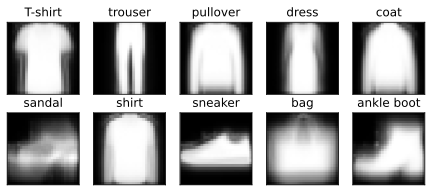

In [5]:
d2l.show_images(P_xy.reshape(10, 28, 28), 2, 5,
                titles=data.text_labels(range(10)), cmap='gray');

The resulting templates look like soft, blurred outlines of the ten
garments. Because each template is simply the per-pixel average of its
class, that blur reflects genuine variation in how garments are shaped and
positioned. Any model that matches the per-pixel frequencies of the data,
whether or not it assumes independence, produces the exact same templates;
the blur belongs to the data, not to the assumption. What the naive
assumption adds is the claim that these averages, together with the prior,
are all there is to know. To see what that claim implies, we can draw
synthetic images from the model by flipping an independent coin with
probability $\hat\theta_{iy}$ for every pixel.

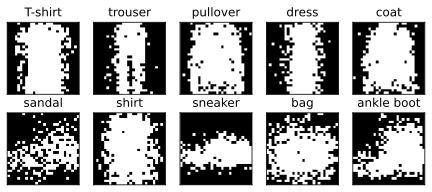

In [6]:
rng = np.random.default_rng()
samples = (rng.random((1000, 10, 784)) < P_xy).astype(np.float32)
d2l.show_images(samples[0].reshape(10, 28, 28), 2, 5,
                titles=data.text_labels(range(10)), cmap='gray');

Each sample captures the right overall silhouette, but its edges are ragged
and speckled because every boundary pixel is decided by its own independent
coin flip. We can quantify that visual difference directly. Scanning across
a row of a real image, ink and background switch only a few times; in a
model sample they should switch much more frequently. Below we compare both
the overall ink fraction and the average number of ink-to-background
switches per row across the training set and across 1,000 generated samples
per class.

In [7]:
def switches(images):  # ink/background changes along a row, mean per row
    return np.abs(np.diff(images.reshape(-1, 28, 28), axis=2)).sum(axis=2).mean()

print(f'ink fraction: data {X.mean():.3f}, samples {samples.mean():.3f}')
print('switches per row, data:   ',
      np.round([switches(X[Y == y]) for y in range(10)], 1))
print('switches per row, samples:',
      np.round([switches(samples[:, y]) for y in range(10)], 1))

ink fraction: data 0.498, samples 0.498
switches per row, data:    [3.8 3.2 3.1 3.1 3.1 3.  3.3 1.5 3.1 2.6]
switches per row, samples: [5.1 4.1 4.8 4.7 4.8 8.2 5.4 4.  8.2 5.9]


The samples carry the same overall amount of ink as the real data, as they
must since every pixel has the right marginal probability. Yet they jump
between ink and background far more often: roughly 5 switches per row
instead of 3 for pullovers, and about 8 instead of 3 for sandals and bags.
Real garments have smooth contours because neighboring pixels tend to agree,
and that local agreement is precisely what the independence assumption
discards.

### Checking the Assumption

Generated samples show the independence assumption failing across the image
as a whole; a single pair of pixels pins it down with concrete numbers.
Consider two neighboring pixels along the bottom hem of pullovers, in row 26
at columns 14 and 15. If those two pixels were conditionally independent
given the class, the fraction of pullovers with both inked would equal the
product of their individual ink fractions. Let us compare that product with
the actual joint frequency in both the training pullovers and the 1,000
sampled pullovers.

In [8]:
i, j = 26 * 28 + 14, 26 * 28 + 15     # two neighbouring hem pixels
for name, Z in (('data', X[Y == 2]), ('model', samples[:, 2])):
    p_i, p_j, both = Z[:, i].mean(), Z[:, j].mean(), (Z[:, i] * Z[:, j]).mean()
    print(f'{name:5s}: P(i)={p_i:.2f}  P(j)={p_j:.2f}  '
          f'P(i)P(j)={p_i * p_j:.2f}  P(i,j)={both:.2f}')

data : P(i)=0.55  P(j)=0.55  P(i)P(j)=0.30  P(i,j)=0.54
model: P(i)=0.56  P(j)=0.56  P(i)P(j)=0.31  P(i,j)=0.31


Each pixel is inked in roughly 55% of the pullovers. Under independence,
both should be inked together in $0.55\times0.55\approx30\%$ of them. In the
actual data, both are inked in 54% of pullovers—nearly as often as either
pixel alone. A pullover's hem either reaches row 26 or stops short of it, so
these two neighboring pixels act almost like a single feature recorded
twice. The model's samples, by construction, match the product.

### Test Accuracy

To classify the test set, we use the affine form
the equation. We compute the weights $w_{iy}$ and
offsets $b_y$ from `P_xy` and `P_y`, score every test image against all ten
classes in a single matrix multiplication, and save the predictions for the
analysis that follows. Softmax regression reached about 83% accuracy with
scores of this exact same form; how much do we give up by counting instead?

In [9]:
W = np.log(P_xy) - np.log1p(-P_xy)              # w_iy, log-odds per pixel
b = np.log1p(-P_xy).sum(axis=1) + np.log(P_y)   # b_y, score of a blank image
s = X_test @ W.T + b                            # s_y(x), shape (10000, 10)
pred = s.argmax(axis=1)
print(f'test accuracy {(pred == Y_test).mean():.4f}, training accuracy '
      f'{((X @ W.T + b).argmax(axis=1) == Y).mean():.4f}')

test accuracy 0.7059, training accuracy 0.7171


Naive Bayes classifies about 71% of the test images correctly, far above the
10% baseline of random guessing. Because counting involves no randomness,
this number is completely deterministic from run to run; we will put an
error bar on its sampling uncertainty shortly.

The training accuracy is just as informative. On the 60,000 images used to
fit it, the model is right 72% of the time—only one percentage point higher
than on unseen test images. A model that had overfit its training set would
show a wide gap between the two; here there is almost none. The errors are
therefore not caused by a shortage of training data. The model makes the
same mistakes on its own training set as on new images because its
assumptions are too restrictive: in the language of
that section, the error is dominated by bias rather than
variance. Collecting more images would barely move the needle. What we need
is a better set of parameters, and our softmax regression comparison below
will confirm that a much better linear classifier exists within the very
same model family.

These log scores also let us check what would have happened had we evaluated
the raw product the equation directly. Since each score is
the natural logarithm of a Bayes numerator, dividing by $\log 10$ gives its
base-10 exponent. Let us compare the numerators against the smallest
positive single-precision number and the smallest *normal* double-precision
number, below which double precision begins to lose accuracy.

In [10]:
log10 = s / np.log(10)                     # decimal exponent of each numerator
print(f'log10 of the numerators: largest {log10.max():.0f}, smallest '
      f'{log10.min():.0f}, median best {np.median(log10.max(axis=1)):.0f}')
f32 = -149 * np.log(2)     # log of 2**-149, the smallest positive float32
f64 = -1022 * np.log(2)    # log of 2**-1022, the smallest normal float64
print(f'images whose best numerator underflows float32: '
      f'{(s.max(axis=1) < f32).mean():.2f}')
print(f'numerators below the smallest normal float64: {(s < f64).mean():.2f}, '
      f'images whose best one is: {(s.max(axis=1) < f64).mean():.4f}')
print(f'accuracy of the raw float64 product: '
      f'{(np.exp(s).argmax(axis=1) == Y_test).mean():.4f}')

log10 of the numerators: largest -32, smallest -1002, median best -81
images whose best numerator underflows float32: 0.96
numerators below the smallest normal float64: 0.44, images whose best one is: 0.0003
accuracy of the raw float64 product: 0.7058


The Bayes numerators span roughly $10^{-32}$ down to $10^{-1000}$, with the
winning class of a typical image sitting near $10^{-81}$. For 96% of test
images, even the largest of the ten numerators falls below the smallest
positive single-precision float, so raw single-precision products would see
ten zeros and fail to classify them at all. In double precision, 44% of all
numerators drop below the smallest normal float64, though almost all of
those belong to losing classes. The largest numerator stays representable
for all but three images in ten thousand, so the raw float64 product matches
the log-space accuracy to within one image in ten thousand. Still, double
precision survives 784 pixels only with modest headroom: at $10^{-81}$ for a
typical winning score, an input four times as long would underflow float64
as well. Working in log space keeps every score comfortably within ordinary
floating-point range.

## Evaluating the Classifier

A headline accuracy of 71% immediately raises three questions. How precise
is that estimate? Which confusions account for the remaining 29%? And can we
trust the probabilities the classifier reports?

### Error Bars

Our test accuracy is an average over 10,000 random test images, so a
different test sample would produce a slightly different number. Each test
image yields a single Bernoulli outcome, right or wrong. This is the same
coin toss that opened the chapter, flipped once per test image, so the
observed accuracy $\hat p$ is the sample mean of $n$ flips and has standard
error $\sqrt{\hat p(1-\hat p)/n}$ (that section). For
$\hat p=0.706$ and $n=10{,}000$,

$$\sqrt{\frac{0.706\cdot0.294}{10^4}}\approx0.0046,\qquad 1.96\times0.0046\approx0.009,$$

giving a 95% confidence interval extending about $0.9$ percentage points in
either direction. The bootstrap (that section) provides a
second, formula-free check: we resample the test images with replacement,
recompute the accuracy on each resample, and take the middle 95% of the
resulting distribution.

In [11]:
rng = np.random.default_rng()
correct = pred == Y_test                           # per-image 0/1 outcomes
n, p = len(correct), correct.mean()
boot = correct[rng.integers(0, n, (1000, n))].mean(axis=1)  # 1,000 resamples
print(f'accuracy {p:.4f}, bootstrap 95% interval '
      f'({np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f})')
print(f'binomial half-width 1.96 se = {1.96 * np.sqrt(p * (1 - p) / n):.4f}')

accuracy 0.7059, bootstrap 95% interval (0.697, 0.715)
binomial half-width 1.96 se = 0.0089


The bootstrap interval runs from about 0.70 to 0.715, matching the binomial
half-width of $0.009$. We should therefore report the accuracy as
$71\%\pm0.9$ points; the digits after the decimal point in "70.59%" are
sampling noise. Note that when comparing two classifiers on the exact same
test set, their errors are correlated, so a paired analysis of per-image
differences is much sharper than comparing two separate confidence intervals
(exercise 5).

### Confusions and Weights

Overall accuracy tells us how often the classifier errs; the confusion
matrix of that section tells us *how* it errs. Following the
convention of that section, rows correspond to predicted
classes and columns to true classes, so each column traces where the 1,000
test images of a given garment end up.

In [12]:
conf = np.zeros((10, 10), dtype=int)
np.add.at(conf, (pred, Y_test), 1)       # N[i, j]: class j predicted as i
print(conf)

[[748   9   8  50   2   0 218   0   0   0]
 [  0 907   0  53   3   0   4   0   3   0]
 [ 14  18 665   5 372   0 232   0  14   0]
 [122  48  12 808 104   2  93   0  68   7]
 [  8  16 242  45 483   0 222   0   6   0]
 [  0   0   0   0   0 680   0   5   1   0]
 [ 83   0  50  35  25   2 167   0  20   0]
 [  1   0   0   0   0 232   1 893  55 113]
 [ 24   2  23   4  11   9  63   0 832   4]
 [  0   0   0   0   0  75   0 102   1 876]]


A $10\times10$ table of counts is much easier to read when we pull out its
largest mistakes. Below we print the six largest off-diagonal entries,
formatted as true class to predicted class, along with each class's
individual accuracy (its diagonal entry divided by its column sum).

In [13]:
names = data.text_labels(range(10))
off = conf - np.diag(np.diag(conf))      # errors only
order = np.argsort(off, axis=None, kind='stable')[::-1][:6]  # largest first
pairs = [f'{names[t]}->{names[q]} {off[q, t]}'  # true -> predicted
         for q, t in zip(*np.unravel_index(order, off.shape))]
print(', '.join(pairs[:3]))
print(', '.join(pairs[3:]))
print('per-class accuracy:', np.round(np.diag(conf) / conf.sum(axis=0), 2))

coat->pullover 372, pullover->coat 242, sandal->sneaker 232
shirt->pullover 232, shirt->coat 222, shirt->T-shirt 218
per-class accuracy: [0.75 0.91 0.66 0.81 0.48 0.68 0.17 0.89 0.83 0.88]


The mistakes are heavily concentrated. Coats are misclassified as pullovers
372 times and pullovers as coats 242 times; shirts are mistaken for
pullovers, coats, and t-shirts more than 200 times each; and sandals are
mistaken for sneakers 232 times. Trousers (91%) and sneakers (89%) are
easy, whereas coats (48%) and shirts (17%) are much harder. These are the
exact same two confusion groups that softmax regression struggled with in
that section—the four upper-body garments and the three
types of footwear—but the counted model fares far worse on the upper-body
group: softmax regression recognized shirts 40% to 60% of the time, while
naive Bayes manages only about one in six.

Is 71% simply the ceiling for a linear classifier on binary pixels? Softmax
regression defines hyperplanes of the exact same form, but chooses its
weights by minimizing the cross-entropy of $p(y\mid\mathbf x)$. Let us train
softmax regression on these same binary pixels with minibatch stochastic
gradient descent so that only the fitting procedure differs. The update uses
the result from that section that the gradient of the cross-entropy
with respect to the logits is simply the predicted probability vector minus
the one-hot label.

In [14]:
rng = np.random.default_rng()
W_sr, b_sr = np.zeros((10, 784)), np.zeros(10)
for epoch in range(20):                  # minibatches of 256 images
    for idx in np.array_split(rng.permutation(len(X)), len(X) // 256):
        O = X[idx] @ W_sr.T + b_sr                   # logits
        E = np.exp(O - O.max(axis=1, keepdims=True))
        G = E / E.sum(axis=1, keepdims=True) - np.eye(10)[Y[idx]]
        W_sr -= 0.05 * G.T @ X[idx] / len(idx)       # mean-loss gradient
        b_sr -= 0.05 * G.mean(axis=0)
pred_sr = (X_test @ W_sr.T + b_sr).argmax(axis=1)
conf_sr = np.zeros((10, 10), dtype=int)
np.add.at(conf_sr, (pred_sr, Y_test), 1)
print(f'accuracy: softmax regression {(pred_sr == Y_test).mean():.3f}, '
      f'naive Bayes {(pred == Y_test).mean():.3f}')
print('pullover<->coat errors: softmax regression',
      conf_sr[2, 4] + conf_sr[4, 2], 'naive Bayes', conf[2, 4] + conf[4, 2])

accuracy: softmax regression 0.821, naive Bayes 0.706
pullover<->coat errors: softmax regression 267 naive Bayes 614


Softmax regression reaches about 83% accuracy, twelve percentage points
ahead of naive Bayes, and roughly halves the errors between pullovers and
coats. The linear model family itself is therefore not the bottleneck; the
gap comes entirely from how counting sets the weights. We will pinpoint why
counting distorts those weights when we inspect calibration next.

First, looking directly at the naive Bayes weights shows what features the
classifier relies on to separate two classes. The score difference between
pullover and coat is an affine function with weight vector
$\mathbf w_{\text{pullover}}-\mathbf w_{\text{coat}}$: whenever pixel $i$
is inked rather than blank, it shifts the score toward pullover by entry $i$
of this vector. Let us plot this difference vector as a $28\times28$ image,
with red favoring pullover and blue favoring coat, and print its largest
entry along with the underlying counts.

largest |weight| 3.1 nats at row 0, column 1: inked in 21 pullovers and 0 coats


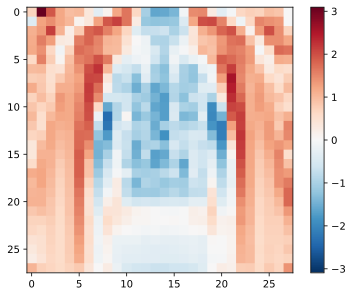

In [15]:
w = (W[2] - W[4]).reshape(28, 28)        # pullover minus coat, in nats
m = np.abs(w).max()
d2l.plt.imshow(w, cmap='RdBu_r', vmin=-m, vmax=m)
d2l.plt.colorbar()
k = np.abs(w).argmax()
print(f'largest |weight| {m:.1f} nats at row {k // 28}, column {k % 28}: '
      f'inked in {n_x[2, k]:.0f} pullovers and {n_x[4, k]:.0f} coats')

Red pixels run along both sides of the image and across the top rows, where
pullovers are inked more often than coats. Blue pixels fill the torso with
weights near $-1$, though it would be a mistake to read those blue pixels as
strong evidence for a coat when inked. Remember that each weight measures
the score of an inked pixel *relative* to a blank one. A torso pixel is
inked in roughly 99% of pullovers and more than 99.5% of coats, so seeing it
inked barely moves the needle—about $-0.01$ nats. The weight of $-1$ is
actually what the model adds in favor of pullover on the rare occasion when
a torso pixel is left blank. In practice, the decision is made along the
sides. Meanwhile, the single largest weight, about 3 nats, sits in a corner
that is inked in roughly twenty pullovers and zero coats, meaning its
magnitude is controlled largely by the Laplace pseudo-count rather than by
abundant data.

Before we critique the generative fit further, notice one genuine advantage
it holds over a discriminative model. If some pixels are missing at test
time, say hidden behind an occlusion, naive Bayes simply drops their factors
from the product. Under the generative model this is mathematically exact,
because marginalizing $p(x_i\mid y)$ over both values of an unobserved $x_i$
sums to $1$. Softmax regression has no corresponding marginalization rule
and must impute values for the missing pixels
(exercise 9).

### Calibration

The class scores do more than rank the ten classes. Exponentiating them
recovers the Bayes numerators, and normalizing recovers the denominator
$p(\mathbf x)$ we dropped earlier, so the model's posterior probabilities
are simply the softmax of its scores:

$$p(y\mid\mathbf x)=\frac{\exp s_y(\mathbf x)}{\sum_{y'}\exp s_{y'}(\mathbf x)}.$$

Every prediction therefore comes with a stated confidence, namely the
largest of these posterior probabilities. As in that section,
a classifier is *calibrated* when its stated confidences match empirical
frequencies: among all predictions made with confidence $c$, a fraction $c$
should actually be correct. To test calibration, we group the test images
into confidence bins and compare the average claimed confidence with the
actual accuracy in each bin.

The *expected calibration error* (ECE) condenses this table into a single
number: the weighted average of the gap between claimed confidence and
achieved accuracy across bins, weighted by the fraction of test images in
each bin. Below we compute the softmax in its numerically stable form by
subtracting the largest score first (that section),
and we also print the median gap between the highest and second-highest
class scores.

In [16]:
post = np.exp(s - s.max(axis=1, keepdims=True))      # softmax, stably
post /= post.sum(axis=1, keepdims=True)
c = post.max(axis=1)                                 # claimed confidence
print(f'mean confidence {c.mean():.3f}, accuracy {correct.mean():.3f}')
edges, ece = [0, 0.9, 0.99, 0.999, 1], 0
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (c > lo) & (c <= hi)
    ece += m.mean() * abs(c[m].mean() - correct[m].mean())
    print(f'({lo}, {hi}]: {m.sum():5d} images, claimed {c[m].mean():.3f}, '
          f'achieved {correct[m].mean():.3f}')
top2 = np.sort(s, axis=1)[:, -2:]
print(f'ECE {ece:.2f}, median top-two score gap '
      f'{np.median(top2[:, 1] - top2[:, 0]):.0f} nats')

mean confidence 0.992, accuracy 0.706
(0, 0.9]:   257 images, claimed 0.726, achieved 0.350
(0.9, 0.99]:   297 images, claimed 0.961, achieved 0.384
(0.99, 0.999]:   265 images, claimed 0.996, achieved 0.419
(0.999, 1]:  9181 images, claimed 1.000, achieved 0.735
ECE 0.29, median top-two score gap 61 nats


The result is striking: on average, the model claims 99% confidence while
getting only 71% of its predictions right. Roughly 92% of all test images
land in the top bin, where the model claims certainty to three decimal
places yet is right only about 73% of the time. In the three lower bins, it
claims between 73% and 99.6% confidence while achieving only 35% to 42%
accuracy. Because every bin is overconfident, the expected calibration error
equals the gap between mean confidence and accuracy, about 0.29—compared
with under 0.03 for softmax regression in that section. The
ranking of confidences still carries useful signal, since accuracy rises
from bin to bin, but the stated probabilities cannot be taken at face value.

The culprit is the same phenomenon we saw at the pullover hem: correlated
pixels are counted as independent pieces of evidence. The simplest version
of this failure is a single feature duplicated several times, and the
arithmetic takes three lines. Consider two classes with priors $\pi_0$ and
$\pi_1$ and a feature $x$ with likelihood ratio
$r(x)=p(x\mid y=1)/p(x\mid y=0)$. Suppose our dataset contains $k$ identical
copies of $x$. Because all $k$ copies always agree, they carry no more
information than a single copy, so the true log posterior odds are
$\log(\pi_1/\pi_0)+\log r(x)$. Naive Bayes, however, treats the copies as
conditionally independent, multiplies $k$ identical factors $p(x\mid y)$,
and reports

$$\log\frac{\pi_1}{\pi_0}+k\log r(x).$$

Duplicated evidence multiplies the log-odds by $k$. When the priors are
equal, multiplying the log-odds by a positive constant never flips its sign,
so naive Bayes predicts the exact same class for every $k$, yet it claims
posterior odds of $\bar r^k$ where $\bar r$ is right, with
$\bar r=\max(r,1/r)$. This is the second result in this section worth
remembering: the ranking survives, while the confidence collapses.

A concrete number makes the inflation vivid. Take a clue that is right 80%
of the time, with $p(x=1\mid y=1)=0.8$ and $p(x=1\mid y=0)=0.2$, so that
$r=4$ when the clue is active. A single copy gives the right confidence of
$0.80$. Storing two, three, four, and five copies pushes naive Bayes's
claimed confidence to $0.94$, $0.985$, $0.996$, and $0.999$, even though its
predictions are still right only 80% of the time. Duplicating the word
"free" in our two-word spam filter does the same thing: the odds of the
first message jump from $9$ to $\frac23\cdot4.5^2\cdot3=40.5$, raising its
stated spam probability to $0.976$.

Be careful not to overstate how safe the ranking is: the argument above
relies on equal priors, and that caveat matters. With prior odds
$\pi_1/\pi_0=1/5$ and $r=4$, a single copy gives posterior odds of $4/5$ and
correctly predicts class $0$; two copies give $16/5$ and flip the prediction
to class $1$. Repeated evidence can overwhelm a prior that a single
observation should not override. The ranking stays intact only when the
evidence already agrees with the prior or when one copy alone outweighs it.

On Fashion-MNIST, the 784 pixels are not literal copies of one another, but
large patches of them are tightly correlated. Our two hem pixels behaved
almost like one feature counted twice, and dozens of such correlated regions
pile up to create a median gap of about 60 nats between the highest and
second-highest class scores. Since $e^{-60}\approx10^{-26}$, the softmax
turns a 60-nat gap into a reported confidence of $1.000$. That naive Bayes
still ranks the classes usefully despite extreme overconfidence is a classic
property of the model [@Domingos.Pazzani.1997]. Even so, the ranking is
not completely unscathed: correlated patches vary in size, so a broad region
of redundant pixels can easily outvote a smaller region carrying
independent information. This imbalance is a plausible explanation for the
twelve percentage points lost to softmax regression, which can down-weight
pixels that merely echo their neighbors, though our experiment alone does
not isolate that mechanism.

Overconfidence has a remarkably simple post-hoc repair, which we only name
here. Temperature scaling (that section) divides every class
score by a single scalar $T$ fitted on held-out validation data, leaving the
class rankings completely unchanged; for $k$ identical copies and equal
priors, setting $T=k$ recovers the exact posterior. Exercise
8 fits $T$ for our counted
model. Nor is overconfidence unique to naive Bayes: deep neural networks can
suffer from the same bias, though typically to a lesser degree and depending
on their architecture and training recipe
[@Guo.Pleiss.Sun.Weinberger.2017], so a reliability check is
good practice for any classifier whose probabilities will drive decisions.

One natural question remains open. With 6,000 images per class, the
discriminative fit won handily. With very few training examples, however,
the ranking often reverses: @Ng.Jordan.2002 proved that naive Bayes
parameters converge after a number of examples logarithmic in the dimension
$d$, whereas logistic regression can require a number linear in $d$.
Exercise 10 explores
this crossover on pullovers and coats.

## Summary

Bayes' rule turns a generative model of how each class produces its inputs
into a classifier, but estimating an unrestricted table of
$p(\mathbf x\mid y)$ over $10^{236}$ binary images is impossible. Assuming
conditional independence among features given the class reduces the model to
a single frequency per class and feature, smoothed by one Laplace
pseudo-count, so training reduces to counting. Because the log of the naive
Bayes numerator is affine in binary features, Bernoulli naive Bayes is a
linear classifier in the exact same model family as softmax regression.

On Fashion-MNIST, this counted classifier reaches about $71\%\pm0.9$
percentage points, twelve points below softmax regression fitted directly on
the same binary pixels. It reports an average confidence of 99%, because
correlated pixels are treated as independent evidence and duplicated
evidence multiplies the log-odds. That extreme overconfidence shows why
calibration should be checked whenever a classifier's probabilities are used
in practice.

## Exercises

1. **XOR and the naive assumption.** The four points $(0,0)$, $(0,1)$,
   $(1,0)$ and $(1,1)$ carry the labels $y=x_1\oplus x_2$, that is $0$, $1$,
   $1$ and $0$. Each point occurs once in the training set.
    1. Compute the maximum-likelihood estimates of $p(y)$ and
       $\theta_{iy}=p(x_i=1\mid y)$, and the class scores of all four
       points. Which predictions does the naive Bayes rule
       the equation make?
    1. Show that no choice of Bernoulli naive Bayes parameters classifies all
       four points correctly, using the affine form
       the equation of the scores. Why can degenerate parameters
       $\theta_{iy}\in\{0,1\}$ not help? (Each class must give positive
       probability to its own two points.)
    1. Replace the two factors $p(x_1\mid y)\,p(x_2\mid y)$ by a joint table
       $p(x_1,x_2\mid y)$. In the language of Bayesian networks
       [@Koller.Friedman.2009], this adds the edge between $x_1$ and
       $x_2$ that the right panel of the figure
       shows. Estimate this model from the four points and show that it
       classifies them correctly. Why is its class score no longer affine in
       $\mathbf x$?
    1. Within one class, let $x_1$ and $x_2$ be independent fair bits and let
       $x_3=x_1\oplus x_2$. Show that every pair of the three features is
       independent. Compare the probability of each of the eight patterns
       with the product of the three marginals. Why can a check of all
       pairwise correlations within a class not confirm the assumption
       the equation?

1. **Naive Bayes as logistic regression.** Consider two classes
   $y\in\{0,1\}$ with the prior $\pi_1=p(y=1)$ and the Bernoulli parameters
   $\theta_{iy}=p(x_i=1\mid y)$.
    1. Show that the naive Bayes posterior is
       $p(y=1\mid\mathbf x)=\operatorname{sigmoid}(\mathbf w^\top\mathbf x+b)$
       with $\operatorname{sigmoid}(z)=1/(1+e^{-z})$ and
       $w_i=\log\frac{\theta_{i1}(1-\theta_{i0})}{\theta_{i0}(1-\theta_{i1})}$.
       Express $b$ through the $\theta_{iy}$ and $\pi_1$. Which sign does $w_i$
       have for a pixel that is inked more often in class $1$ than in class
       $0$?
    1. Show that, conversely, every pair $(\mathbf w,b)$ arises from some
       choice of $\theta_{iy}\in(0,1)$ and $\pi_1\in(0,1)$. Naive Bayes and
       logistic regression therefore define the same set of posteriors and
       differ in how they fit it.
    1. Suppose the two classes of the training set are linearly separable.
       How does the conditional likelihood of logistic regression change when
       a separating $(\mathbf w,b)$ is multiplied by a factor $t\to\infty$?
       What does this imply for the maximum-likelihood estimate of
       $(\mathbf w,b)$? Which $(\mathbf w,b)$ does naive Bayes with Laplace
       smoothing return on the same data?

1. **Gaussian class-conditionals.** A single feature has
   $x\mid y=0\sim\mathcal N(0,1)$ and $x\mid y=1\sim\mathcal N(0,4)$, and both
   classes have prior $1/2$.
    1. Find the set of $x$ that the Bayes classifier assigns to class $1$.
       Why can no threshold on $x$ produce this set? Which transformed
       feature turns the boundary into a threshold?
    1. In $d$ dimensions, Gaussian naive Bayes with class-specific variances
       has the class score
       $$\log p(y)-\sum_{i=1}^d\left[\frac{(x_i-\mu_{iy})^2}{2\sigma_{iy}^2}+\frac12\log\left(2\pi\sigma_{iy}^2\right)\right].$$
       Show that the boundary between two classes is a quadratic surface
       without cross terms $x_ix_j$.
    1. Two classes in two dimensions have equal priors and the
       class-conditionals $\mathcal N(\mathbf 0,\boldsymbol\Sigma_+)$ and
       $\mathcal N(\mathbf 0,\boldsymbol\Sigma_-)$ with
       $\boldsymbol\Sigma_\pm=\left(\begin{smallmatrix}1&\pm\rho\\\pm\rho&1\end{smallmatrix}\right)$
       for some $0<\rho<1$. Show that the difference of the two class scores
       is $2\rho x_1x_2/(1-\rho^2)$, so that the Bayes classifier assigns
       class $+$ exactly when $x_1x_2>0$, and that each single score also
       depends on $x_1^2+x_2^2$. The two classes have the same marginals, so
       Gaussian naive Bayes is at chance even with unlimited data. Under
       $\mathcal N(\mathbf 0,\boldsymbol\Sigma_+)$,
       $P(x_1x_2>0)=\frac12+\frac1\pi\arcsin\rho$ (Sheppard's formula). Find
       the Bayes error as a function of $\rho$, and evaluate it for
       $\rho=0.1$ and $\rho=0.9$.

1. **Two event models for text.** A vocabulary $V$ has the four words
   *goal*, *match*, *vote* and *poll*. The training set contains three
   sports documents, "goal goal match", "goal match match" and "match vote",
   and three politics documents, "vote poll poll", "vote vote match" and
   "poll vote". The multinomial model treats a document as a sequence of
   independent word draws from a class-specific distribution over $V$. The
   Bernoulli model records for each word of $V$ only whether it occurs in the
   document.
    1. Estimate both models with Laplace smoothing. For the multinomial
       model, add $1$ to each word count of a class and $|V|$ to the class's
       total count. For the Bernoulli model, estimate the probability that a
       word occurs by $(n_{iy}+1)/(n_y+2)$, where $n_{iy}$ counts the
       class-$y$ documents that contain word $i$.
    1. Classify the document "goal match poll poll" with both models. Which
       words drive each decision?
    1. Concatenate a document with itself $k$ times. How do the log posterior
       odds of the two models change? In real text, a word that has occurred
       once in a document tends to occur again [@Church.Gale.1995], a
       finding that exercise 3
       of that section reproduces. Which assumption of the
       multinomial model does this violate?

1. [code] **Paired comparison.** The text compared naive Bayes with softmax
   regression by their accuracies, `pred` against `pred_sr`.
    1. Bootstrap the per-image difference in correctness, using the same
       resampled indices for both models, and report a 95% interval for the
       difference of the accuracies.
    1. Compare the width of this interval with that of the two marginal
       intervals and with the unpaired standard error
       $\sqrt{p_1(1-p_1)/n+p_2(1-p_2)/n}$. Compute the correlation of the two
       vectors of correctness, and use it to explain why pairing helps.
    1. Count the test images that both models get wrong, that only naive
       Bayes gets right, and that only softmax regression gets right. Which of
       these counts determine the difference of the accuracies? What would the
       table look like for a model that differs from naive Bayes only by
       correcting some of its errors?

1. **Duplicated and correlated evidence.** Two classes have equal priors,
   and a binary feature has $p(x=1\mid y=1)=0.8$ and $p(x=1\mid y=0)=0.2$.
    1. A pipeline stores the feature $k$ times. Find the smallest $k$ for
       which naive Bayes claims at least 99.9% confidence for predictions that
       are right 80% of the time.
    1. Now store two copies that agree only partly: given $y$, the second
       copy equals the first with probability $q$ and is otherwise a fresh
       draw from the same class-conditional distribution. Show that both
       copies have the same marginal as $x$, so naive Bayes still claims
       $16/17\approx0.94$ when both copies are $1$. Show that the correct
       posterior is $r/(1+r)$ with $r=4(0.8+0.2q)/(0.2+0.8q)$, and evaluate it
       for $q\in\{1,0.75,0.5,0.25,0\}$. How does the over-count depend on the
       correlation of the copies?
    1. Show that dividing every class score by $T=k$ before the softmax
       restores the correct posterior in (a). Why are equal priors needed
       for this? (The prior term is divided by $k$ too.)

1. [code] **Label shift.** Under label shift
   (that section), the target prior
   $p_T(y)$ differs from the source prior $p_S(y)$, while
   $p(\mathbf x\mid y)$ stays the same.
    1. Show that the posterior under the target prior is
       $p_T(y\mid\mathbf x)\propto p_S(y\mid\mathbf x)\,p_T(y)/p_S(y)$. Why
       does naive Bayes need no retraining to use it?
    1. Build a test set in which pullovers make up 90% of the images: all
       1,000 test pullovers and 111 images drawn at random from the other
       classes. Compare the accuracy of `pred` on it with that of the
       corrected rule of (a), with $p_T(\text{pullover})=0.9$ and
       $p_T(y)=1/90$ for every other class.
    1. The correction adds $\log 9\approx2.2$ nats to the pullover score and
       subtracts $2.2$ from the others. Compare this with the score gaps of
       the `#mdl-naive-bayes-calibration-3` cell and explain the size of the
       change you measured in (b).

1. [code] **Temperature scaling.** ● Exercise
   6 shows that dividing the
   class scores by $T=k$ undoes a $k$-fold duplication of features. For
   Fashion-MNIST the effective duplication is unknown, and temperature
   scaling [@Guo.Pleiss.Sun.Weinberger.2017] fits $T$ on held-out data
   instead: the posterior becomes the softmax of $s_y(\mathbf x)/T$.
    1. Refit the model on the first $50{,}000$ training images, and choose
       $T$ by minimizing the average negative log-likelihood of the
       posterior on the remaining $10{,}000$. Why does $T$ not change the
       test accuracy?
    1. Apply the fitted $T$ to the scores of the same $50{,}000$-image model
       on the test set, and repeat the reliability table of the
       `#mdl-naive-bayes-calibration-3` cell with the bin edges $0$, $0.5$,
       $0.7$, $0.9$, $0.99$ and $1$. Compare the mean claimed confidence with
       the accuracy.
    1. In the setting of exercise
       6, show that the
       standard deviation of the score gap on real data is $\sqrt k$ times
       the standard deviation that the model predicts. Compute the square of
       this ratio for the pairs pullover/coat, t-shirt/shirt, and
       pullover/shirt, and compare it with the fitted $T$.
    1. Apply the prior correction of exercise
       7 to the temperature-scaled
       posterior, on the test set built there. Why does the corrected prior
       change many more predictions after temperature scaling?

1. [code] **Missing pixels.** Hide a random half of the pixels of every test
   image with a Boolean mask `M` of the shape of `X_test` that is `True` for
   the visible pixels.
    1. Show that under the model, marginalizing a hidden pixel out of
       $p(\mathbf x\mid y)$ removes its factor, so that the score of the
       visible pixels is $\log p(y)+\sum_{i\text{ visible}}\log p(x_i\mid y)$.
       Implement it with two matrix products,
       `(X_test * M) @ np.log(P_xy).T + ((1 - X_test) * M) @ np.log(1 - P_xy).T`
       plus the log prior, and compare the accuracy with the 71% of the full
       images.
    1. Instead fill the hidden pixels with $0$, with $1$, or with the mean of
       the training images, and score with the affine form. Explain each
       accuracy from the equation; what does filling
       with $0$ add to the score of every class?
    1. Score softmax regression from the text on the images with hidden
       pixels set to $0$. Which operation does a discriminative model lack
       that the generative model used in (a)?

1. [extended] **Generative versus discriminative learning.** ●●
   @Ng.Jordan.2002 compare naive Bayes with logistic regression,
   which by exercise 2
   fits the same family of posteriors by maximizing the conditional
   likelihood. They prove that the naive Bayes parameters approach their
   population values after a number of examples logarithmic in $d$. For
   logistic regression, the number of examples needed to approach its
   asymptotic error is at most linear in $d$, and in the worst case it is
   also at least linear in $d$. On many of their $15$ datasets, naive Bayes
   has the lower test error for small training sets and logistic regression
   for large ones.
    1. Let each class have at least $m$ training examples. Use Hoeffding's
       inequality (that section) and a union bound to show that
       all $2d$ unsmoothed estimates $\hat\theta_{iy}$ of a two-class model
       lie within $\varepsilon$ of their population values with probability
       at least $1-\delta$ when
       $$m\ge\frac{\log(4d/\delta)}{2\varepsilon^2}.$$
       Evaluate the bound for $d=784$, $\varepsilon=0.05$ and $\delta=0.05$.
    1. A uniform bound on $|\hat\theta_{iy}-\theta_{iy}|$ does not by itself
       bound the change of the class scores. Why not, for the pixels with
       $\theta_{iy}$ close to $0$ or $1$, such as the corner pixel that
       carries the largest pullover-coat weight in the text? What must be
       assumed about the $\theta_{iy}$ for the scores to converge at the rate
       of the parameters?
    1. Restrict the data to pullovers and coats. For the total training-set
       sizes $n\in\{10,20,50,100,200,500,1000,2000,5000\}$ and for all
       $12{,}000$ images, draw random training subsets that contain both
       classes, $20$ for each size up to $n=200$ and $5$ for each larger
       size. Fit naive Bayes with Laplace smoothing, and logistic regression
       without weight decay. For small $n$ the training data are linearly
       separable, and by exercise
       2c the logistic
       loss has no minimizer, so run a fixed number of full-batch gradient
       steps from zero initialization. Plot the average test errors of both
       classifiers against $n$ on a logarithmic axis with `d2l.plot`. In
       which range of $n$, if any, does naive Bayes have the lower error?
    1. Repeat (c) with synthetic data for which the naive assumption holds:
       draw balanced labels and sample each pixel independently from
       $\mathrm{Bernoulli}(\theta_{iy})$, with the $\theta_{iy}$ estimated
       from all training images of the two classes. How do the two learning
       curves and their asymptotic errors change?
    1. Theorem 4 of @Ng.Jordan.2002 bounds the excess error of naive
       Bayes by the probability that the score gap of the population model
       falls near zero. Compare this probability for real pixels and for the
       synthetic data of (d), and explain how this comparison, together with
       the asymptotic errors of (c) and (d), accounts for the two pairs of
       learning curves.

[Discussions](https://d2l.discourse.group/t/1101)